# Финальный экзамен. Анализ данных в Python

Спиридонов М.Д., ФИБ

Данные: `NHL-playoffs-2026.xlsx`, события матчей плей-офф НХЛ 2025/26. Площадку рисую функцией из `rink.py`, файл лежит рядом с ноутбуком.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rink import plot_rink

%matplotlib inline
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 100)
sns.set_theme(style='whitegrid')

## Задача 1

Читаем Excel. В файле первый столбец `Unnamed: 0` это старый индекс, который попал в таблицу при сохранении, его выкидываю, после этого столбцов 38, как в условии. Дату перевожу в datetime, строки сортирую по игре и номеру события (они и так в таком порядке, но на всякий случай).

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx')
events = events.drop(columns='Unnamed: 0')
events['Date'] = pd.to_datetime(events['Date'])
events = events.sort_values(['Game ID', 'Play ID']).reset_index(drop=True)
events.shape

(29710, 38)

In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Пока смотрел на данные, заметил, что у трёх игроков фамилии с битой кодировкой: `Juraj SlafkovskÃ½`, `Tim StÃ¼tzle`, `Oskar BÃ¤ck`. Это UTF-8, прочитанный как latin-1. Проверил, что других вариантов написания этих фамилий в данных нет (то есть на подсчёты это не влияет), но раз уж заметил, чиню, чтобы в таблицах было нормально.

In [4]:
name_cols = [c for c in events.columns if ('Player' in c or 'Goalie' in c) and not c.startswith('#')]

def fix_name(s):
    if isinstance(s, str) and 'Ã' in s:
        return s.encode('latin-1').decode('utf-8')
    return s

for c in name_cols:
    events[c] = events[c].map(fix_name)

events['Play Type'].value_counts()

Play Type
hit                5621
faceoff            4995
shot-on-goal       4137
stoppage           3958
blocked-shot       2798
missed-shot        2643
giveaway           2604
penalty             804
takeaway            779
goal                486
period-start        272
period-end          272
delayed-penalty     259
game-end             82
Name: count, dtype: int64

## Задача 2

Счёт игры беру из последнего события игры (это всегда `game-end`), там в `Cumulated Away Score` и `Cumulated Home Score` лежит итоговый счёт. Число овертаймов это номер последнего периода минус 3.

In [5]:
last = events.groupby('Game ID').last()
print(last['Play Type'].unique())

games = last[['Date', 'Away Team', 'Home Team', 'Cumulated Away Score', 'Cumulated Home Score']].copy()
games.columns = ['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score']

def outcome(period):
    ot = period - 3
    if ot <= 0:
        return 'Final'
    elif ot == 1:
        return 'Final/OT'
    else:
        return 'Final/%dOT' % ot

games['Outcome'] = last['Period'].apply(outcome)
print(games.columns)
games.iloc[-5:, -4:]

<StringArray>
['game-end']
Length: 1, dtype: str
Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='str')


,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


In [6]:
games['Outcome'].value_counts()

Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

82 игры, 60 закончились в основное время, 18 в первом овертайме, 4 во втором. Последние пять строк совпадают с примером.

## Задача 3

In [7]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return '%s - %s (%d - %d, %s, %s)' % (g['Home Team'], g['Away Team'], g['Home Score'], g['Away Score'],
                                           g['Outcome'], g['Date'].strftime('%Y-%m-%d'))

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## Задача 4

In [8]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

В среднем в матче 5.9 гола, медиана 6, половина матчей между 5 и 7 голами. Разброс при этом приличный: от 1 до 15, стандартное отклонение 2.26.

## Задача 5

Величина дискретная, рисую `countplot`. Чтобы на оси были все значения от 1 до 15 (в том числе те, которых не было, например 12), передаю `order`.

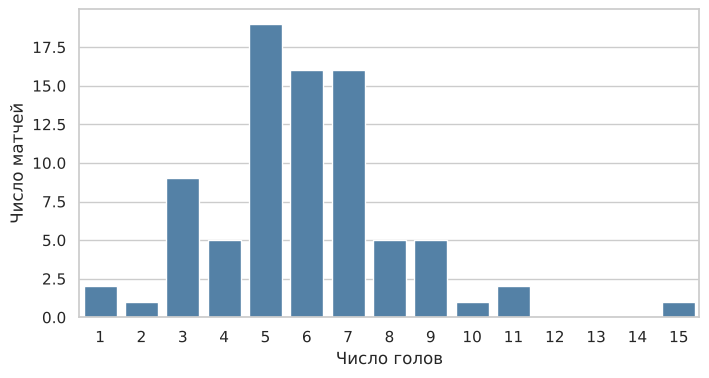

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64

In [9]:
plt.figure(figsize=(8, 4))
sns.countplot(x=games['Total Score'], order=range(1, 16), color='steelblue')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.show()

games['Total Score'].value_counts().sort_index()

Распределение с одной вершиной. Мода 5 голов (19 матчей), на 5, 6 и 7 голов приходится 51 матч из 82. Слева хвост короткий: всего три матча с 1-2 голами, для такого счёта нужно, чтобы оба вратаря отыграли почти на ноль. Справа хвост длиннее, 8-11 голов было в 13 матчах, плюс один матч совсем в стороне, 15 голов (Colorado - Minnesota 9:6). Среднее 5.93 и медиана 6 при этом почти совпадают, перекоса из-за выбросов нет.

## Задача 6

In [10]:
total = games['Total Score']
print([gameInfo(i) for i in games.index[total == total.min()]])
print([gameInfo(i) for i in games.index[total == total.max()]])

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Оба самых нерезультативных матча закончились 1:0 в овертайме, то есть за 60 минут основного времени не было забито ни одной шайбы. Самый результативный матч Colorado - Minnesota 9:6.

## Задача 7

Беру 12 столбцов с игроками на льду плюс два столбца с вратарями, через `melt` делаю длинную таблицу (игра, фамилия) и считаю уникальные фамилии в каждой игре.

In [11]:
on_ice_cols = [c for c in events.columns if 'Player on the Ice' in c]
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]

on_ice = events.melt(id_vars='Game ID', value_vars=on_ice_cols + goalie_cols, value_name='Player')
on_ice = on_ice.dropna(subset=['Player']).drop_duplicates(['Game ID', 'Player'])

player_count = on_ice.groupby('Game ID')['Player'].nunique()

players_per_game = pd.DataFrame({'Game Info': [gameInfo(i) for i in player_count.index],
                                 'Player Count': player_count.values},
                                index=player_count.index)
players_per_game.sort_values('Player Count', ascending=False).head()

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)",40
2025030112,"Buffalo Sabres - Boston Bruins (2 - 4, Final, 2026-04-21)",39
2025030215,"Buffalo Sabres - Montréal Canadiens (3 - 6, Final, 2026-05-14)",39
2025030413,"Vegas Golden Knights - Carolina Hurricanes (5 - 4, Final/2OT, 2026-06-06)",39
2025030235,"Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)",39


In [12]:
players_per_game['Player Count'].value_counts()

Player Count
38    73
39     8
40     1
Name: count, dtype: int64

В обычной игре 38 человек: по 18 полевых и по вратарю с каждой стороны. Больше получается, когда вратаря меняли по ходу матча. Больше всего игроков в матче Montréal - Buffalo 3:8, там обе команды меняли вратарей (Luukkonen и Lyon у Buffalo, Dobes и Fowler у Montréal), итого 40.

В примере из условия для этой игры стоит 41. Я перепроверил список фамилий руками, уникальных ровно 40. Скорее всего в примере в множество попал ещё и `NaN` из пустых ячеек.

## Задача 8

Нужные события: `shot-on-goal`, `goal`, `missed-shot`. Сначала определяю, в какие ворота бросает команда. Если хозяева защищают левые ворота (`Home Team's Defending Side == 'left'`), то хозяева бросают в правые ($X = 89$), гости в левые ($X = -89$), при `right` наоборот. Хозяева или гости бросают, видно по тому, совпадает ли `Team Making the Play` с `Home Team`.

Расстояние до ближайшей точки створа по формуле из условия:

$$
d(x,y) = \begin{cases}
\sqrt{(x-X)^2 + (y+3)^2}, & y < -3,\\
|x - X|, & -3 \le y \le 3,\\
\sqrt{(x-X)^2 + (y-3)^2}, & y > 3.
\end{cases}
$$

Чтобы не писать три ветки, считаю $d_y$ как расстояние от $y$ до отрезка $[-3, 3]$ (ноль внутри отрезка), и тогда $d = \sqrt{(x-X)^2 + d_y^2}$ во всех трёх случаях. Всё через `np.where`, без циклов.

In [13]:
shot_types = ['shot-on-goal', 'goal', 'missed-shot']
is_shot = events['Play Type'].isin(shot_types)

is_home = events['Team Making the Play'] == events['Home Team']
home_left = events["Home Team's Defending Side"] == 'left'

# X ворот, в которые бросает команда
events['Goal X'] = np.where(is_home, np.where(home_left, 89, -89),
                                     np.where(home_left, -89, 89))

x = events['X Coordinate on the Ice Rink']
y = events['Y Coordinate on the Ice Rink']
dy = np.where(y < -3, y + 3, np.where(y > 3, y - 3, 0))
d = np.sqrt((x - events['Goal X']) ** 2 + dy ** 2)

events['Shot Length'] = np.where(is_shot, d, np.nan)
events[is_shot][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


In [14]:
events[is_shot].groupby('Play Type')['Shot Length'].describe()

,count,mean,std,min,25%,50%,75%,max
Play Type,,,,,,,,
goal,486.0,26.006,28.090,1.0,9.000,19.013,31.941,187.216
missed-shot,2643.0,34.014,22.313,0.0,16.155,32.249,49.041,185.068
shot-on-goal,4137.0,37.405,29.990,0.0,16.643,33.377,48.508,188.215


7266 бросков, значения как в примере (12.207, 12.000, 29.411 и т.д.), пропусков в координатах у бросков нет.

Уже здесь видно, что голы забивают с меньшего расстояния: в среднем 26 футов (медиана 19), а броски в створ и мимо делают в среднем с 34-37 футов. Максимумы под 185-188 футов, это бросок почти от своих ворот через всю площадку, о них в следующем пункте.

## Задача 9

Точные броски это `shot-on-goal` плюс `goal`, неточные это `missed-shot`. Групп две и они разного размера (4623 против 2643), поэтому нужно рисовать не количество, а плотность, и нормировать каждую группу отдельно. В `displot` это `stat='density'` и `common_norm=False`. Если оставить `common_norm=True` (по умолчанию), то обе гистограммы нормируются на общее число бросков и меньшая группа просто окажется ниже.

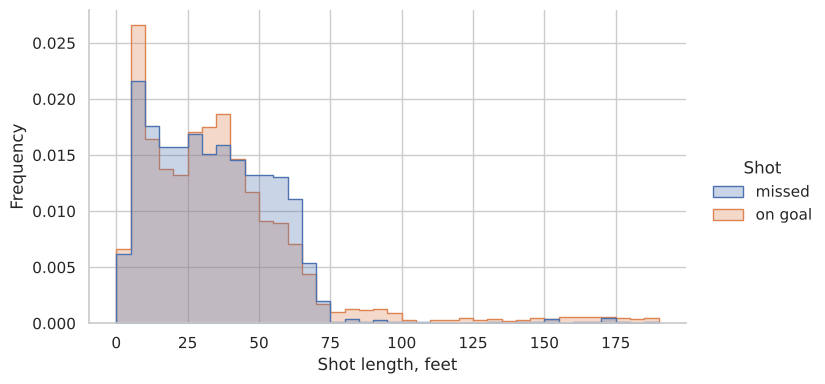

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
missed,2643.0,34.014,22.313,0.0,16.155,32.249,49.041,185.068
on goal,4623.0,36.207,29.997,0.0,15.000,31.828,47.011,188.215


In [15]:
shots = events[is_shot].copy()
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')

g = sns.displot(data=shots, x='Shot Length', hue='Shot', stat='density', common_norm=False,
                bins=range(0, 195, 5), element='step', alpha=0.3, height=4, aspect=1.8)
g.set_axis_labels('Shot length, feet', 'Frequency')
plt.show()

shots.groupby('Shot')['Shot Length'].describe()

Обе плотности с максимумом на 5-15 футах, то есть прямо у ворот. У точных бросков этот пик заметно выше, а на 30-70 футах выше уже плотность неточных: издалека чаще мажут. После 70 футов неточные броски почти заканчиваются, а у точных есть длинный хвост от 90 до 190 футов, то есть броски со своей половины площадки. Вывод из гистограммы: чем ближе бросок, тем больше шанс попасть в створ, а дальних бросков мимо ворот в данных почти нет.

Чтобы понять, откуда хвост, посмотрел на броски дальше 100 футов и на то, был ли в этот момент вратарь в воротах соперника. Тут вылезла особенность данных: у победных голов в овертайме (и ещё у нескольких событий) состав на льду не записан вообще, число игроков 0 и все фамилии пустые. Если тупо смотреть на столбец с вратарём, такие голы выглядят как голы в пустые ворота. Поэтому для событий без состава подтягиваю вратаря из предыдущего события той же игры (`ffill`), а пустыми воротами считаю только случай, когда состав записан, а вратаря в нём нет. Эти столбцы пригодятся ещё в задачах 21 и 22.

In [16]:
no_lineup = (events["# of Away Team's Players on the Ice"] == 0) & (events["# of Home Team's Players on the Ice"] == 0)
print(no_lineup.sum(), 'событий без состава:', events.loc[no_lineup, 'Play Type'].value_counts().to_dict())

for col in goalie_cols:
    filled = events.groupby('Game ID')[col].ffill()
    events[col + ' (filled)'] = np.where(no_lineup, filled, events[col])

# вратарь соперника в момент события
events['Opp Goalie'] = np.where(is_home, events["Away Team's Goalie (filled)"], events["Home Team's Goalie (filled)"])
events['Empty Net'] = events['Opp Goalie'].isna() & ~no_lineup

shots = events[is_shot].copy()
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')
shots['On Goal'] = shots['Play Type'] != 'missed-shot'

far = shots[shots['Shot Length'] > 100]
print(len(far), 'бросков дальше 100 футов')
pd.crosstab(far['Play Type'], far['Empty Net'], margins=True)

111 событий без состава: {'period-end': 36, 'game-end': 31, 'goal': 22, 'penalty': 19, 'stoppage': 3}
183 бросков дальше 100 футов


Empty Net,False,True,All
Play Type,,,
goal,14,3,17
missed-shot,2,21,23
shot-on-goal,143,0,143
All,159,24,183


Из 183 бросков дальше 100 футов 143 это броски в створ, и ни один из них не в пустые ворота. Так что хвост точных бросков со своей половины я объясняю так.

Это в основном не прицельные броски, а длинные вбросы шайбы из своей зоны: выброс при игре в меньшинстве, dump-in и т.п. Если шайба летит в сторону ворот и вратарь её останавливает, статистика НХЛ записывает это как бросок в створ. А если такая же шайба прошла мимо, никакого `missed-shot` не возникает, это просто проброс или шайба уехала за ворота, и записывается остановка или вбрасывание. Получается смещение отбора: далёкие броски попадают в данные почти только тогда, когда они оказались в створе. Поэтому хвост есть у точных бросков и нет у неточных.

Игра в пустые ворота в концовке даёт всего 24 броска из 183 (3 гола и 21 промах), и они в основном в группе неточных, так что хвост точных не из-за них.

Ещё есть 14 голов с расстояния больше 100 футов при вратаре в воротах. Гол через всю площадку при вратаре случается раз в несколько сезонов, а не 14 раз за один плей-офф, так что это почти наверняка ошибки в координатах (точка записана не на той половине). То есть часть хвоста, особенно по голам, это мусор в данных, но основную массу (143 броска в створ) объясняет эффект отбора выше.

## Задача 10

Незаблокированные броски: `shot-on-goal`, `goal`, `missed-shot`. По каждой паре (игра, команда) делю число точных на число всех.

In [17]:
numshots = shots.groupby(['Game ID', 'Team Making the Play'])['On Goal'].agg(['size', 'sum'])
numshots.columns = ['Unblocked Shots', 'Shots on Goal']
numshots['Share of Shots on Goal'] = numshots['Shots on Goal'] / numshots['Unblocked Shots']
numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [18]:
numshots['Share of Shots on Goal'].describe()

count    164.000
mean       0.639
std        0.085
min        0.353
25%        0.583
50%        0.639
75%        0.689
max        0.860
Name: Share of Shots on Goal, dtype: float64

164 строки, 82 игры по две команды. В среднем в створ идёт 64% незаблокированных бросков, то есть примерно каждый третий бросок проходит мимо. Величина довольно устойчивая: межквартильный размах всего 0.58-0.69, хотя в отдельных матчах бывает и 0.35, и 0.86. Разница между двумя командами в одном матче обычно небольшая. По-моему, точность в отдельном матче это скорее случайная величина вокруг общего уровня 0.6-0.7, чем характеристика команды, следующий пункт это подтверждает.

## Задача 11

In [19]:
avgnumshots = numshots.groupby('Team Making the Play')['Share of Shots on Goal'].mean()
print(avgnumshots.nlargest(5))
print(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64
Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64


In [20]:
# для интерпретации: сколько игр сыграла каждая команда
games_played = pd.concat([games['Home Team'], games['Away Team']]).value_counts()
pd.DataFrame({'Share': avgnumshots, 'Games': games_played}).sort_values('Share', ascending=False)

,Share,Games
Edmonton Oilers,0.706,6
Philadelphia Flyers,0.684,10
Dallas Stars,0.670,6
Minnesota Wild,0.656,11
Colorado Avalanche,0.653,13
Anaheim Ducks,0.649,12
Montréal Canadiens,0.644,19
Los Angeles Kings,0.642,4
Boston Bruins,0.638,6
Ottawa Senators,0.635,4


Разброс между командами маленький: от 0.55 у Pittsburgh до 0.71 у Edmonton, а 14 команд из 16 сидят в полосе 0.60-0.68. И с успехом в плей-офф это никак не связано: Edmonton и Philadelphia с лучшей точностью вылетели в первом и втором раунде, а финалисты Vegas (22 игры) и Carolina (19 игр, третья с конца по точности) в середине и внизу списка. Крайние значения к тому же посчитаны по 6 играм (Edmonton, Pittsburgh), так что это во многом шум. Точность бросков сама по себе команды почти не различает.

## Задача 12

Бросок в створ это `shot-on-goal` и `goal` (гол тоже попал в створ). Считаю по парам (игра, команда), потом усредняю по командам.

In [21]:
sog = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
per_game = sog.groupby(['Game ID', 'Team Making the Play'])['Play Type'].agg(
    Shot='size', Goal=lambda s: (s == 'goal').sum())
avgshots = per_game.groupby('Team Making the Play').mean()
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


Совпадает с примером. По броскам все команды в узком диапазоне 23-32 за игру, по голам разброс в разы: от 1.25 у Los Angeles и Ottawa до 3.7 у Minnesota.

## Задача 13

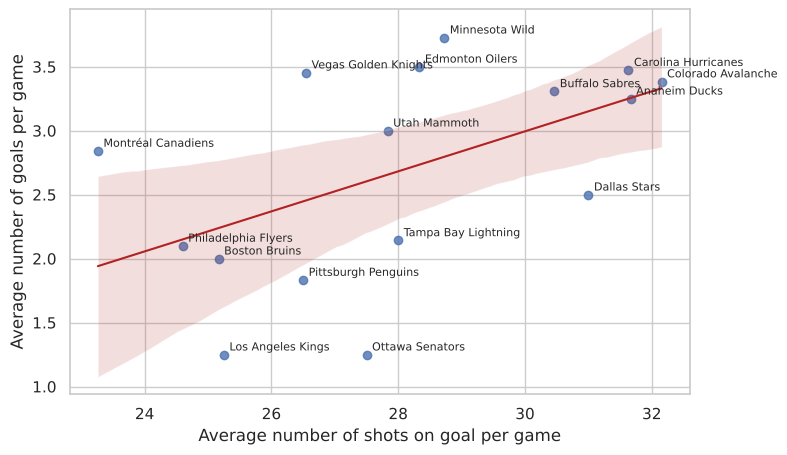

корреляция: 0.521


In [22]:
plt.figure(figsize=(8, 5))
ax = sns.regplot(data=avgshots, x='Shot', y='Goal', line_kws={'color': 'firebrick', 'lw': 1.5})
for team, row in avgshots.iterrows():
    ax.annotate(team, (row['Shot'], row['Goal']), fontsize=8, xytext=(4, 3), textcoords='offset points')
plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.show()

print('корреляция:', round(avgshots['Shot'].corr(avgshots['Goal']), 3))

Прямая идёт вверх, корреляция 0.52, то есть какая-то положительная связь есть, но слабая: доверительная полоса широкая, точки сильно разбросаны вокруг прямой. При одинаковых 27-28 бросках за игру Ottawa забивает 1.25, а Edmonton и Minnesota 3.5-3.7. Реализация у команд отличается гораздо сильнее, чем число бросков. Плюс точек всего 16, и у половины команд среднее посчитано по 4-7 играм, так что одна-две команды (Ottawa, Los Angeles, Montréal) заметно тянут прямую. Я бы сказал, что связь скорее видна, чем нет, но надёжной её назвать нельзя. В задаче 22 я к этому возвращаюсь.

## Задача 14

Считаю все удары: в створ, голы, промахи и заблокированные.

In [23]:
all_shot_types = ['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot']
shots_per_game = events[events['Play Type'].isin(all_shot_types)].groupby('Game ID').size()
idxmax = shots_per_game.idxmax()
print(gameInfo(idxmax), '-', shots_per_game.max(), 'ударов')
shots_per_game.sort_values(ascending=False).head()

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20) - 208 ударов


Game ID
2025030132    208
2025030164    169
2025030413    163
2025030126    156
2025030175    154
dtype: int64

Матч с двумя овертаймами, почти 100 минут игры, отсюда и рекорд.

## Задача 15

Гости должны бросать в левые ворота, хозяева в правые. Если хозяева защищают левые ворота, то так всё и есть. Если хозяева защищают правые, то броски обеих команд надо отразить, $(x,y)\mapsto(-x,-y)$. Поэтому отражаю координаты всех событий, где `Home Team's Defending Side == 'right'`. Ниже видно, что в этом матче это как раз нечётные периоды, как и написано в условии.

Про заблокированные броски: в данных `Team Making the Play` для них это команда, которая бросала (игрок #1 заблокировавший, игрок #2 бросавший), а координаты это точка блока, в зоне атаки бросавшей команды. Проверка ниже: после отражения все удары Carolina на правой половине, все удары Ottawa на левой, кроме трёх дальних бросков со своей половины.

В примере кода из условия `plt.axis('even')` и `plt.tight_layout(0.1)`, в моей версии matplotlib это не работает, пишу `plt.axis('equal')` и `plt.tight_layout(pad=0.1)`.

In [24]:
game_shots = events[(events['Game ID'] == idxmax) & events['Play Type'].isin(all_shot_types)].copy()
home_team = games.loc[idxmax, 'Home Team']
away_team = games.loc[idxmax, 'Away Team']

flip = game_shots["Home Team's Defending Side"] == 'right'
game_shots['x'] = np.where(flip, -game_shots['X Coordinate on the Ice Rink'], game_shots['X Coordinate on the Ice Rink'])
game_shots['y'] = np.where(flip, -game_shots['Y Coordinate on the Ice Rink'], game_shots['Y Coordinate on the Ice Rink'])

print(game_shots.groupby('Period')["Home Team's Defending Side"].first())
pd.crosstab([game_shots['Team Making the Play'], game_shots['Play Type']], np.sign(game_shots['x']))

Period
1    right
2     left
3    right
4     left
5    right
Name: Home Team's Defending Side, dtype: str


x                                  -1.0   1.0
Team Making the Play Play Type               
Carolina Hurricanes  blocked-shot     0    26
                     goal             0     3
                     missed-shot      0    34
                     shot-on-goal     2    44
Ottawa Senators      blocked-shot    28     0
                     goal             2     0
                     missed-shot     32     0
                     shot-on-goal    36     1

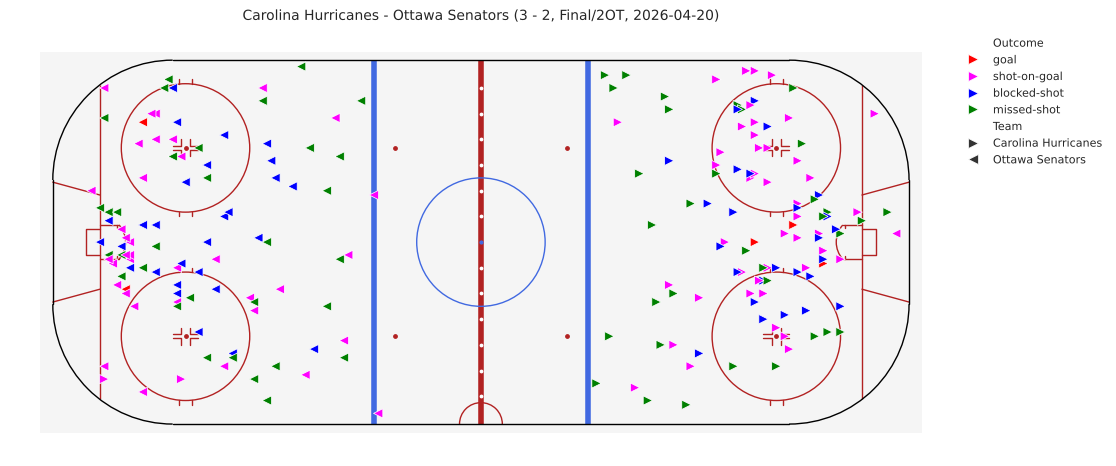

Play Type,blocked-shot,goal,missed-shot,shot-on-goal
Team Making the Play,,,,
Carolina Hurricanes,26,3,34,46
Ottawa Senators,28,2,32,37


In [25]:
plt.figure(figsize=(11, 4.5))
plot_rink()
ax = sns.scatterplot(data=game_shots, x='x', y='y', hue='Play Type', style='Team Making the Play',
                     hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                     markers={home_team: '>', away_team: '<'},
                     palette={'goal': 'red', 'shot-on-goal': 'magenta', 'blocked-shot': 'blue', 'missed-shot': 'green'},
                     s=45, zorder=2)
plt.axis('equal')
plt.axis('off')
handles, labels = ax.get_legend_handles_labels()
labels = ['Outcome' if l == 'Play Type' else 'Team' if l == 'Team Making the Play' else l for l in labels]
ax.legend(handles, labels, loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)
plt.title(gameInfo(idxmax), fontsize=10)
plt.tight_layout(pad=0.1)
plt.show()

game_shots.groupby(['Team Making the Play', 'Play Type']).size().unstack(fill_value=0)

Carolina (хозяева, маркеры вправо) бросает в правые ворота, Ottawa (маркеры влево) в левые. Все пять голов из пятачка перед воротами. Заблокированные броски в основном от синей линии и из кругов вбрасывания, это броски защитников, которые перекрывают по дороге. Carolina бросала больше (109 ударов против 99), что для хозяев в овертаймовом матче логично.

## Задача 16

In [26]:
goals = events[events['Play Type'] == 'goal']
goals['Player in the Event #1'].value_counts().head(10)

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: count, dtype: int64

## Задача 17

Передачи это игроки #2 и #3 в событии `goal`, складываю оба столбца в один.

In [27]:
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']]).dropna()
assists.value_counts().head(10)

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

## Задача 18

In [28]:
points = pd.DataFrame({'Goals': goals['Player in the Event #1'].value_counts(),
                       'Assists': assists.value_counts()}).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']
points.sort_values(['Points', 'Goals'], ascending=False).head(10)

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16


По голам первые Howden (14), Dorofeyev (12) и Stankoven (11), по передачам Eichel (20) и Marner (19). По очкам с отрывом Marner: 10 + 19 = 29, дальше Eichel 22 и Blake 20. Наверху почти одни игроки Vegas и Carolina, что понятно: финалисты сыграли 22 и 19 матчей, а вылетевшие в первом раунде 4-7.

## Задача 19

Броски в створ игрока (`shot-on-goal` и `goal`, игрок #1) делю на число его игр. Игры считаю по появлению фамилии в столбцах «на льду» (таблица `on_ice` из задачи 7). Число игр вывожу рядом, без него средние по 1-4 матчам ни о чём не говорят.

In [29]:
games_by_player = on_ice.groupby('Player').size()

sog_rate = pd.DataFrame({'Shots on Goal': sog['Player in the Event #1'].value_counts()})
sog_rate['Games'] = games_by_player
sog_rate['Shots on Goal per Game'] = sog_rate['Shots on Goal'] / sog_rate['Games']
sog_rate.sort_values('Shots on Goal per Game', ascending=False).head(10)

,Shots on Goal,Games,Shots on Goal per Game
Player in the Event #1,,,
Jason Robertson,30,6,5.000
Dylan Guenther,27,6,4.500
Nikita Kucherov,31,7,4.429
Matt Boldy,48,11,4.364
Quinton Byfield,17,4,4.250
Darren Raddysh,28,7,4.000
Joel Eriksson Ek,24,6,4.000
Alex Laferriere,15,4,3.750
David Pastrnak,22,6,3.667


Первый Robertson из Dallas, 5 бросков в створ за игру, но всего за 6 игр. Из тех, кто прошёл дальше, выделяются Boldy (4.4 за 11 игр) и MacKinnon (3.6 за 13). Короткую серию проще отыграть на высоком среднем, поэтому в топе много игроков команд, вылетевших в первом раунде.

## Задача 20

In [30]:
hit_rate = pd.DataFrame({'Hits': events.loc[events['Play Type'] == 'hit', 'Player in the Event #1'].value_counts()})
hit_rate['Games'] = games_by_player
hit_rate['Hits per Game'] = hit_rate['Hits'] / hit_rate['Games']
hit_rate.sort_values('Hits per Game', ascending=False).head(10)

,Hits,Games,Hits per Game
Player in the Event #1,,,
Lawson Crouse,38,6,6.333
Alex Turcotte,6,1,6.000
Alexander Petrovic,6,1,6.000
Yakov Trenin,51,9,5.667
Dylan Cozens,22,4,5.500
Vasily Podkolzin,32,6,5.333
Carl Grundstrom,15,3,5.000
Marcus Foligno,55,11,5.000
Ivan Barbashev,110,22,5.000


In [31]:
# то же самое, но хотя бы 5 игр
hit_rate[hit_rate['Games'] >= 5].sort_values('Hits per Game', ascending=False).head(10)

,Hits,Games,Hits per Game
Player in the Event #1,,,
Lawson Crouse,38,6,6.333
Yakov Trenin,51,9,5.667
Vasily Podkolzin,32,6,5.333
Marcus Foligno,55,11,5.000
Ivan Barbashev,110,22,5.000
Owen Tippett,29,6,4.833
William Carrier,91,19,4.789
Colton Dach,23,5,4.600
Cole Smith,100,22,4.545


Без ограничения на число игр в топ попадают Turcotte и Petrovic с 6 хитами в единственной игре. Среди тех, кто сыграл хотя бы 5 матчей, первые Crouse (6.3 за игру), Trenin (5.7) и Podkolzin (5.3). Самый показательный, по-моему, Barbashev: 5 хитов за игру на дистанции всех 22 матчей Vegas.

## Задача 21

Для каждого гола надо понять, кому его забили. Если забили хозяева, пропустил вратарь гостей, и наоборот. Беру столбец `Opp Goalie` из задачи 9 (там для голов в овертайме вратарь восстановлен из предыдущего события, иначе они выглядели бы как голы в пустые ворота). Гол в пустые ворота никому из вратарей не засчитывается.

Дальше для каждой пары (игра, вратарь), где вратарь хоть раз был на льду, считаю пропущенные и оставляю пары с нулём. Замены при этом учитываются сами собой: вратарь, который вышел на замену и не пропустил, в список попадёт, а тот, кого заменили после пропущенных, нет.

In [32]:
print('голов в пустые ворота:', goals['Empty Net'].sum())

goals_against = goals.dropna(subset=['Opp Goalie']).groupby(['Game ID', 'Opp Goalie']).size()
goals_against.index.names = ['Game ID', 'Goalie']

goalie_games = events.melt(id_vars='Game ID', value_vars=goalie_cols, value_name='Goalie')
goalie_games = goalie_games.dropna(subset=['Goalie']).drop_duplicates(['Game ID', 'Goalie'])
goalie_games = goalie_games.set_index(['Game ID', 'Goalie'])[[]]
goalie_games['Goals Against'] = goals_against
goalie_games['Goals Against'] = goalie_games['Goals Against'].fillna(0).astype(int)

shutouts = goalie_games[goalie_games['Goals Against'] == 0].reset_index()
shutouts['Game Info'] = shutouts['Game ID'].map(gameInfo)
shutouts.sort_values(['Goalie', 'Game ID'])

голов в пустые ворота: 3


,Game ID,Goalie,Goals Against,Game Info
0,2025030126,Andrei Vasilevskiy,0,"Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)"
3,2025030416,Brandon Bussi,0,"Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)"
1,2025030142,Dan Vladar,0,"Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)"
6,2025030146,Dan Vladar,0,"Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)"
5,2025030131,Frederik Andersen,0,"Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)"
7,2025030221,Frederik Andersen,0,"Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)"
2,2025030314,Frederik Andersen,0,"Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)"
4,2025030114,Joonas Korpisalo,0,"Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)"
8,2025030235,Scott Wedgewood,0,"Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)"


In [33]:
print(sorted(shutouts['Goalie'].unique()))
shutouts['Goalie'].value_counts()

['Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood']


Goalie
Frederik Andersen     3
Dan Vladar            2
Andrei Vasilevskiy    1
Brandon Bussi         1
Joonas Korpisalo      1
Scott Wedgewood       1
Name: count, dtype: int64

In [34]:
# проверка на примере замены: Boston - Buffalo 1:6
g = shutouts.loc[shutouts['Goalie'] == 'Joonas Korpisalo', 'Game ID'].iloc[0]
print(gameInfo(g))
print(goalie_games.loc[g])
events[(events['Game ID'] == g) & (events['Play Type'] == 'goal')][
    ['Period', 'Elapsed Time', 'Team Making the Play', 'Player in the Event #1', 'Opp Goalie']]

Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)
                  Goals Against
Goalie                         
Alex Lyon                     1
Jeremy Swayman                6
Joonas Korpisalo              0


,Period,Elapsed Time,Team Making the Play,Player in the Event #1,Opp Goalie
1143,1,04:17,Buffalo Sabres,Peyton Krebs,Jeremy Swayman
1153,1,07:10,Buffalo Sabres,Josh Doan,Jeremy Swayman
1167,1,09:15,Buffalo Sabres,Zach Benson,Jeremy Swayman
1198,1,14:24,Buffalo Sabres,Bowen Byram,Jeremy Swayman
1368,3,05:08,Buffalo Sabres,Beck Malenstyn,Jeremy Swayman
1376,3,06:32,Buffalo Sabres,Alex Tuch,Jeremy Swayman
1456,3,19:20,Boston Bruins,Sean Kuraly,Alex Lyon


Шесть вратарей. Полные сухие матчи: Andersen три за Carolina, Vladar два за Philadelphia, Vasilevskiy и Bussi по одному. Korpisalo и Wedgewood попали за сухой отрезок после замены: Korpisalo в матче Boston - Buffalo 1:6 вышел вместо Swayman, который пропустил все шесть, и сам не пропустил ничего (единственный гол Boston пропустил уже Lyon на другом конце); Wedgewood в матче Colorado - Minnesota 4:3 OT вышел на замену после трёх пропущенных Blackwood и отстоял на ноль до победного гола.

Если бы я не восстанавливал вратаря для голов в овертайме, в список ошибочно попали бы ещё Dobes (Montréal - Tampa 0:1 OT, он пропустил победный гол в овертайме) и Bussi за матч с двумя овертаймами в финале.

## Задача 22

Из задач 9 и 13 видно, что количество бросков объясняет голы слабо, а голы забивают с меньшего расстояния, чем броски вообще. Отсюда вопрос: как вероятность гола зависит от расстояния броска, и с какой дистанции бросать уже почти бесполезно? И второй вопрос вдогонку: чем тогда отличаются результативные команды, если не числом бросков?

Беру все незаблокированные броски, режу по расстоянию на интервалы по 10 футов и в каждом считаю долю голов среди всех бросков и среди бросков в створ. Броски в пустые ворота убираю, чтобы они не портили дальние интервалы.

In [35]:
sh = shots[~shots['Empty Net']].copy()
bins = [0, 10, 20, 30, 40, 50, 60, 70, 200]
sh['Distance'] = pd.cut(sh['Shot Length'], bins, include_lowest=True)

by_dist = sh.groupby('Distance', observed=True)['Play Type'].agg(
    Shots='size', On_Goal=lambda s: (s != 'missed-shot').sum(), Goals=lambda s: (s == 'goal').sum())
by_dist['Goal share, all shots'] = by_dist['Goals'] / by_dist['Shots']
by_dist['Goal share, shots on goal'] = by_dist['Goals'] / by_dist['On_Goal']
by_dist['Share of all goals'] = by_dist['Goals'] / by_dist['Goals'].sum()
by_dist['Share of all shots'] = by_dist['Shots'] / by_dist['Shots'].sum()
by_dist

,Shots,On_Goal,Goals,"Goal share, all shots","Goal share, shots on goal",Share of all goals,Share of all shots
Distance,,,,,,,
"(-0.001, 10.0]",1217,823,146,0.120,0.177,0.302,0.168
"(10.0, 20.0]",1079,656,104,0.096,0.159,0.215,0.149
"(20.0, 30.0]",1128,699,94,0.083,0.134,0.195,0.156
"(30.0, 40.0]",1237,830,68,0.055,0.082,0.141,0.171
"(40.0, 50.0]",976,610,28,0.029,0.046,0.058,0.135
"(50.0, 60.0]",755,411,17,0.023,0.041,0.035,0.104
"(60.0, 70.0]",467,261,7,0.015,0.027,0.014,0.065
"(70.0, 200.0]",367,330,19,0.052,0.058,0.039,0.051


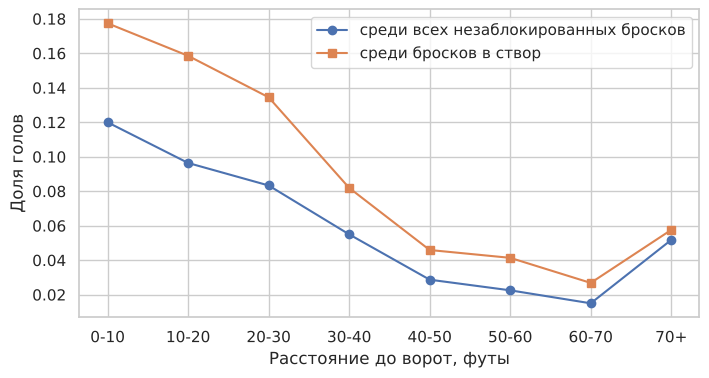

In [36]:
labels = ['%d-%d' % (a, b) for a, b in zip(bins[:-1], bins[1:])]
labels[-1] = '70+'

plt.figure(figsize=(8, 4))
plt.plot(labels, by_dist['Goal share, all shots'], marker='o', label='среди всех незаблокированных бросков')
plt.plot(labels, by_dist['Goal share, shots on goal'], marker='s', label='среди бросков в створ')
plt.xlabel('Расстояние до ворот, футы')
plt.ylabel('Доля голов')
plt.legend()
plt.show()

In [37]:
# по командам: откуда бросают и какая реализация
team_dist = sh.groupby('Team Making the Play')['Shot Length'].agg(
    **{'Median distance': 'median', 'Share within 20 ft': lambda d: (d <= 20).mean()})
team_dist['Goals per 100 shots'] = 100 * sh.groupby('Team Making the Play')['Play Type'].apply(lambda s: (s == 'goal').mean())
team_dist['Avg goals per game'] = avgshots['Goal']
team_dist.sort_values('Goals per 100 shots', ascending=False)

,Median distance,Share within 20 ft,Goals per 100 shots,Avg goals per game
Team Making the Play,,,,
Edmonton Oilers,32.016,0.267,8.642,3.500
Minnesota Wild,34.095,0.341,8.577,3.727
Vegas Golden Knights,29.069,0.355,8.026,3.455
Montréal Canadiens,28.000,0.369,7.930,2.842
Buffalo Sabres,30.447,0.358,6.869,3.308
Colorado Avalanche,33.038,0.287,6.854,3.385
Carolina Hurricanes,32.894,0.310,6.701,3.474
Anaheim Ducks,33.570,0.277,6.678,3.250
Utah Mammoth,33.264,0.274,6.569,3.000


In [38]:
print('доля бросков до 20 футов vs голы за игру:', round(team_dist['Share within 20 ft'].corr(team_dist['Avg goals per game']), 3))
print('реализация vs голы за игру:', round(team_dist['Goals per 100 shots'].corr(team_dist['Avg goals per game']), 3))
print('броски в створ vs голы за игру (задача 13):', round(avgshots['Shot'].corr(avgshots['Goal']), 3))

доля бросков до 20 футов vs голы за игру: -0.026
реализация vs голы за игру: 0.927
броски в створ vs голы за игру (задача 13): 0.521


Вероятность гола падает с расстоянием почти монотонно. С 0-10 футов забивается 12% всех незаблокированных бросков (почти 18% бросков в створ), с 20-30 футов уже 8%, с 30-40 около 5%, дальше 40 футов 2-3%, а дальше 60 футов почти ноль. Половина всех голов (52%) забита с дистанции до 20 футов, хотя таких бросков только треть. Броски от синей линии (50 футов и дальше) дают пару процентов голов, они нужны скорее для добиваний и подправлений, чем для гола напрямую. Последний интервал 70+ опять даёт 5%, но это те самые сомнительные дальние голы из задачи 9, скорее всего ошибки в координатах.

По командам получилось интересно. Дистанция бросков у всех почти одинаковая: медиана 28-35 футов, доля бросков с 20 футов и ближе 25-37%, и с голами за игру эта доля не связана вообще (корреляция около нуля). А реализация, голов на 100 незаблокированных бросков, различается втрое: от 2.8 у Ottawa до 8.6 у Edmonton, и с результативностью связана очень сильно, корреляция 0.93 против 0.52 для числа бросков в задаче 13. То есть в плей-офф команды бросают примерно с одних и тех же точек и примерно одинаково часто, а разницу в голах делает то, какая доля бросков заходит. Что это, умение бросать или удача плюс вратарь соперника, по одному плей-офф не скажешь, для этого нужно было бы сравнить реализацию тех же команд по нескольким сезонам.